# Notebook 2 — The quantum circuit and the six competing sets of inputs

**What this notebook covers**

1. What HSBC actually used the quantum computer for
2. Qubits and gates in plain words
3. Our circuit, drawn small
4. From market data to gate angles
5. What comes out: 327 numbers per quote request
6. How we simulate 109 qubits on a laptop (and proof that the simulation is right)
7. What noise does on a real chip
8. The six feature sets A–F
9. The third suspect: drift, the hidden clock

Code for everything here is in `src/qon/circuit.py`, `simulator.py`, `noise.py` and `feature_sets.py`.

In [1]:
# Set-up: make the project's code importable and keep the output tidy.
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 60); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
%matplotlib inline

## 1. What HSBC actually used the quantum computer for

A common misunderstanding is that the quantum computer made the predictions. It did not. In the HSBC paper the quantum computer is a **pre-processing step**:

```
market data (216 numbers)  ->  QUANTUM CIRCUIT  ->  327 new numbers  ->  ordinary ML model  ->  p(fill)
```

Each row of market data sets the dials of a quantum circuit; the circuit is run and measured; the measurements become a new row of numbers; and those are handed to completely ordinary models (logistic regression, random forests ...). HSBC call this a **projected quantum feature map**.

Their claim: models trained on the *new* numbers predicted fills up to 34% better than models trained on the *original* numbers. Their own catch: this only happened when the circuit ran on real, noisy hardware. When the same circuit was simulated perfectly, there was no gain.

That is why this project asks: **is it quantum, or is it noise?**

## 2. Qubits and gates in plain words

* A **qubit** is the quantum version of a bit. Picture an arrow that can point anywhere on a sphere. "Up" is 0, "down" is 1, and every other direction is a blend.
* A **gate** turns arrows. A two-qubit gate turns two arrows in a way that depends on both, which links them together (*entanglement*).
* When you **measure** a qubit you only ever get 0 or 1, at random, with odds set by where the arrow pointed. So the circuit is run thousands of times (**shots**) and the answers are averaged. The average is called an **expectation value**; it lies between −1 and +1.
* You can measure along three different directions, called **X, Y and Z**. Together the three averages tell you where the arrow pointed.

Our circuit uses one kind of two-qubit gate, the **Heisenberg gate**. Physically it *partially swaps* two neighbouring qubits: angle 0 does nothing, a quarter turn swaps them completely, and anything in between blends them. **The angle is where the market data goes in.**

## 3. Our circuit, drawn small

The real circuit has 109 qubits in a line. Here is the same construction with 6 qubits so that it fits on the screen. Read it left to right:

1. each qubit is put into its own fixed, random starting direction (the `U` boxes);
2. Heisenberg gates on the pairs (0,1), (2,3), (4,5), then on the pairs (1,2), (3,4);
3. the same again (that is the second "Trotter step").

Each gate is written here as its three parts `Rxx`, `Ryy`, `Rzz`; `phi[k]` is the angle of gate number *k*.

In [2]:
from qon.circuit import make_spec, build_qiskit_circuit
small = make_spec(n_features=5, n_qubits=6, trotter_steps=2)
qc, _ = build_qiskit_circuit(small, compact=False)
print(qc.draw("text", fold=150))

      ┌────────────────────┐  ░ ┌────────────────┐┌────────────────┐                ░                                                     ░ »
q_0: ─┤ U(1.5472,5.2006,0) ├──░─┤0               ├┤0               ├─■──────────────░─────────────────────────────────────────────────────░─»
     ┌┴────────────────────┤  ░ │  Rxx(2*phi[0]) ││  Ryy(2*phi[0]) │ │ZZ(2*phi[0])  ░ ┌────────────────┐┌────────────────┐                ░ »
q_1: ┤ U(0.44889,2.5711,0) ├──░─┤1               ├┤1               ├─■──────────────░─┤0               ├┤0               ├─■──────────────░─»
     └┬────────────────────┤  ░ ├────────────────┤├────────────────┤                ░ │  Rxx(2*phi[1]) ││  Ryy(2*phi[1]) │ │ZZ(2*phi[1])  ░ »
q_2: ─┤ U(2.3627,3.4532,0) ├──░─┤0               ├┤0               ├─■──────────────░─┤1               ├┤1               ├─■──────────────░─»
     ┌┴────────────────────┴┐ ░ │  Rxx(2*phi[2]) ││  Ryy(2*phi[2]) │ │ZZ(2*phi[2])  ░ ├────────────────┤├────────────────┤                ░ »
q_3: ┤

In [3]:
spec = make_spec(n_features=98)          # the real one
print(f"qubits: {spec.n_qubits}   gates: {spec.n_slots}   layers: {len(spec.layers)}   outputs: {spec.n_outputs}")
counts = np.bincount(spec.slot_feature, minlength=98)
print(f"each of the 98 inputs sets {counts.min()} or {counts.max()} gates")

qubits: 109   gates: 216   layers: 4   outputs: 327
each of the 98 inputs sets 2 or 3 gates


**Same shape as HSBC's circuit:** 109 qubits, 216 gates in 4 layers. They had 216 inputs, one per gate. We have 98, so we go through the (shuffled) list of inputs again and again until every gate has one. Which input lands on which gate is arbitrary, as it was in the paper; ours is fixed by a seed and written down.

## 4. From market data to gate angles

Raw inputs have wildly different sizes (a price is about 100, a yield about 0.05). Following HSBC's recipe, each input is

1. clipped, so that one freak value cannot dominate;
2. turned into a **z-score**: how many standard deviations above or below normal it is;
3. squashed into a rotation angle: `angle = 2π · tanh(z / 3)`;
4. scaled: `phi = alpha · angle / (4M)` with M = 2 layers-pairs and `alpha = 1`.

"Normal" is measured only on data from before the test window.

In [4]:
from qon.dataset import load_events, FEATURE_COLUMNS
from qon.feature_sets import combine_events
from qon.preprocessing import AngleScaler
ev = load_events()
table = combine_events(ev)
X = table[FEATURE_COLUMNS].to_numpy(float)
is_cal = (table["period"] == "calibration").to_numpy()
history = {FEATURE_COLUMNS.index(c): ev["macro_history"][c].to_numpy() for c in ev["macro_history"].columns}
scaler = AngleScaler.fit(X[is_cal], history=history)
k = int(np.where(~is_cal)[0][0])                       # first event of the test window
show = ["f031_price", "f021_credit_spread", "f041_modified_duration", "f125_zero_trading_days", "f203_vix"]
cols = [FEATURE_COLUMNS.index(c) for c in show]
phi_all = spec.gate_angles(scaler.angles(X))
pd.DataFrame({"raw value": X[k, cols], "z-score": scaler.zscore(X)[k, cols],
              "angle (radians)": scaler.angles(X)[k, cols],
              "gate angle phi": spec.alpha * scaler.angles(X)[k, cols] / (4 * spec.trotter_steps)},
             index=show)

,raw value,z-score,angle (radians),gate angle phi
f031_price,94.5299,0.2838,0.5927,0.0741
f021_credit_spread,0.0148,0.0667,0.1396,0.0175
f041_modified_duration,3.0580,-0.6925,-1.4251,-0.1781
f125_zero_trading_days,0.0000,-0.6691,-1.3787,-0.1723
f203_vix,14.7200,-0.9101,-1.8496,-0.2312


In [5]:
print(f"gate angles across all events: from {phi_all.min():.3f} to {phi_all.max():.3f} radians "
      f"(a full swap is pi/4 = {np.pi / 4:.3f})")

gate angles across all events: from -0.773 to 0.781 radians (a full swap is pi/4 = 0.785)


## 5. What comes out: 327 numbers per quote request

After the gates, every qubit is measured along X, Y and Z. That gives 3 × 109 = **327 averages**, each between −1 and +1. These replace the original 98 inputs.

In [6]:
import time
from qon.simulator import simulate_noiseless
t0 = time.time()
out = simulate_noiseless(spec, phi_all[k:k + 1])[0]
print(f"simulated one 109-qubit circuit exactly in {1000 * (time.time() - t0):.0f} ms")
pd.DataFrame({"<X>": out[:109], "<Y>": out[109:218], "<Z>": out[218:]}).rename_axis("qubit").head(6)

simulated one 109-qubit circuit exactly in 5 ms


,<X>,<Y>,<Z>
qubit,,,
0,0.3567,0.6367,0.6208
1,-0.3765,0.6895,-0.2118
2,0.6675,0.4013,-0.1963
3,0.3925,0.1018,0.5850
4,-0.3988,-0.5922,0.0674
5,-0.2247,-0.7300,-0.1228


## 6. How we simulate 109 qubits on a laptop

Normally you cannot: describing 109 qubits takes 2¹⁰⁹ numbers. But this circuit is *shallow* (only 4 layers), and that changes everything.

**The light cone.** A gate only connects a qubit to its direct neighbour. So after 4 layers, a qubit can only have been influenced by qubits at most 4 steps away. To predict what qubits *a* and *a+1* will show, we only need the 8 qubits around them and 10 gates:

```
qubit:      a-3   a-2   a-1    a    a+1   a+2   a+3   a+4
layer 1:     [=====]     [=====]     [=====]     [=====]
layer 2:           [=====]     [=====]     [=====]
layer 3:                 [=====]     [=====]
layer 4:                       [=====]
                                 ^     ^
                           the two qubits we want to predict
```

Everything outside that triangle cannot affect the answer, so we leave it out. One impossible 109-qubit calculation becomes 55 tiny ones, and the result is **exact**.

In [7]:
from qon.simulator import target_groups, backward_cone
groups = target_groups(spec)
sizes = [(len(backward_cone(spec, g)), len(set(g).union(*[(a, b) for a, b, _ in backward_cone(spec, g)]))) for g in groups]
print(f"{len(groups)} small simulations instead of one big one")
print(f"largest one: {max(s[0] for s in sizes)} gates on {max(s[1] for s in sizes)} qubits")

55 small simulations instead of one big one
largest one: 10 gates on 8 qubits


### Proof that the simulator is right

Every "quantum" number in this project comes from this simulator, so it is checked against three independent Qiskit simulators (`tests/test_simulator_vs_qiskit.py`, 15 tests). Two of those checks, run live:

In [8]:
# Check 1: a 10-qubit version against Qiskit's exact state-vector simulation.
from qiskit.quantum_info import Statevector
from qon.circuit import build_observables
s10 = make_spec(n_features=7, n_qubits=10, trotter_steps=2)
rng = np.random.default_rng(0)
phi10 = s10.gate_angles(2 * np.pi * np.tanh(rng.normal(size=(3, 7)) / 3))
ours = simulate_noiseless(s10, phi10)
qc10, params = build_qiskit_circuit(s10)
obs = build_observables(10)
theirs = np.array([[Statevector(qc10.assign_parameters(dict(zip(params, p)))).expectation_value(o).real
                    for o in obs] for p in phi10])
print(f"10 qubits, 3 events, 30 outputs each: largest difference = {np.abs(ours - theirs).max():.1e}")

10 qubits, 3 events, 30 outputs each: largest difference = 2.4e-15


In [9]:
# Check 2: the full 109-qubit circuit against Qiskit Aer's matrix-product-state simulator,
# which is the simulator HSBC used for their noiseless results.
from qiskit_aer import AerSimulator
from qiskit.quantum_info import SparsePauliOp
qc109, params = build_qiskit_circuit(spec)
bound = qc109.assign_parameters(dict(zip(params, phi_all[k])))
for p in "XYZ":
    for q in range(109):
        bound.save_expectation_value(SparsePauliOp(p), [q], label=f"{p}{q}")
data = AerSimulator(method="matrix_product_state").run(bound).result().data(0)
theirs = np.array([data[f"{p}{q}"] for p in "XYZ" for q in range(109)])
print(f"109 qubits, all 327 outputs: largest difference = {np.abs(out - theirs).max():.1e}")

109 qubits, all 327 outputs: largest difference = 2.0e-10


A difference of 10⁻¹⁰ or smaller is just rounding in the last digits: the two calculations agree.

One more check comes from physics. The Heisenberg gate conserves *total spin*, so if you add up ⟨X⟩ over all 109 qubits you must get the same total whatever the market data was:

In [10]:
some = simulate_noiseless(spec, phi_all[k:k + 5])
print("sum of <X> over all qubits, for 5 different events:", np.round(some[:, :109].sum(axis=1), 10))

sum of <X> over all qubits, for 5 different events: [-11.2013799 -11.2013799 -11.2013799 -11.2013799 -11.2013799]


## 7. What noise does on a real chip

A real quantum chip does not return the exact values above. Four things go wrong:

| Problem | What it is | Effect on our 327 numbers |
|---|---|---|
| **Gate errors** | every gate is slightly imperfect | every number shrinks towards zero |
| **Readout errors** | a 0 is sometimes read as a 1 | more shrinking (IBM's "TREX" method corrects it, at the price of extra scatter) |
| **Shot noise** | an average over 4,096 runs is not exact | random scatter of about ±0.015 |
| **Drift** | the error rates change over minutes and hours | the numbers depend slightly on *when* the circuit ran (section 9) |

Our simulated chip is a copy of a real one: it uses IBM's published calibration data for **ibm_fez** (a Heron-class chip that HSBC also ran on and that is available on IBM's free plan), restricted to the 109 qubits in a row that our circuit would occupy.

In [11]:
import json
from qon import config as C
from qon.noise import make_noise_params
snap = json.loads(C.CHIP_SNAPSHOT.read_text())
params_noise = make_noise_params(spec)
print(f"chip: {snap['backend']}, a chain of {len(snap['chain'])} connected qubits")
print(f"typical error of one two-qubit gate:  {np.median(snap['two_qubit_error']):.2%}   (worst on the chain: {max(snap['two_qubit_error']):.2%})")
print(f"typical readout error:               {np.median(snap['readout_error']):.2%}   (worst: {max(snap['readout_error']):.2%})")
print(f"one Heisenberg gate = {snap['two_qubit_gates_per_heisenberg_gate']} two-qubit gates on the chip")
print(f"typical chance that one Heisenberg gate scrambles its two qubits: {np.median(params_noise.lam_slot):.2%}")

chip: fake_fez, a chain of 109 connected qubits
typical error of one two-qubit gate:  0.39%   (worst on the chain: 1.57%)
typical readout error:               0.85%   (worst: 10.60%)
one Heisenberg gate = 3 two-qubit gates on the chip
typical chance that one Heisenberg gate scrambles its two qubits: 2.08%


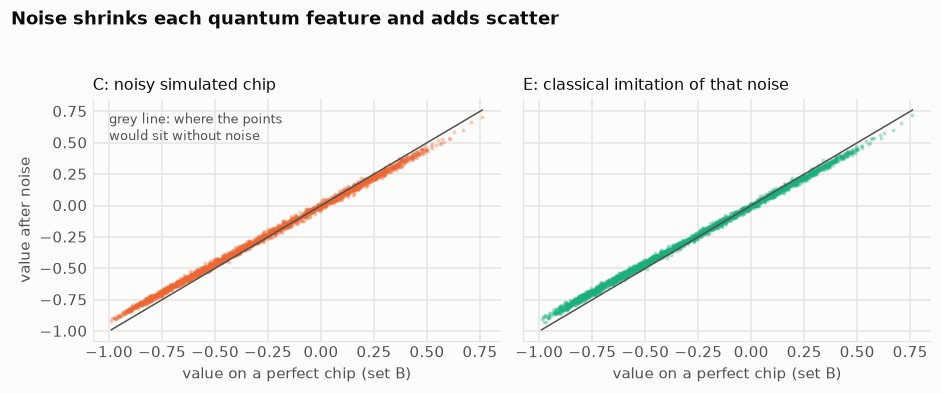

In [12]:
from qon.feature_sets import load_feature_sets
from qon.analysis import fig_noise_effect
fs = load_feature_sets()
sets, events = fs["sets"], fs["events"]
fig_noise_effect(sets, column=30);

In [13]:
info = json.loads((C.DATA_PROCESSED / "feature_sets_meta.json").read_text())
print(f"Across the 327 outputs, noise multiplies a typical value by {info['median_shrink_C_vs_B']:.2f}")
print(f"and adds scatter of about {info['median_jitter_C_vs_B']:.4f}.")
print(f"For comparison, a typical output varies by {info['median_signal_std_B']:.2f} from one event to the next,")
print(f"so the signal is about {info['median_signal_std_B'] / info['median_jitter_C_vs_B']:.0f} times larger than the scatter.")

Across the 327 outputs, noise multiplies a typical value by 0.90
and adds scatter of about 0.0158.
For comparison, a typical output varies by 0.28 from one event to the next,
so the signal is about 18 times larger than the scatter.


**Read the left chart:** each dot is one quote request. Without noise all dots would sit on the grey line. With noise they lie on a slightly flatter line (the *shrink*) with a little fuzz around it (the *scatter*).

**Read the right chart:** this is set E. We took the perfect values and deliberately shrank and jittered them with ordinary random numbers until they looked statistically the same as the noisy chip. No quantum computer needed. If models do as well on E as on the noisy chip, then whatever the noise did, it was nothing a classical computer cannot imitate.

Notice also what noise *cannot* do here: it does not add any information about the market. It can only blur what was there.

## 8. The six feature sets

Every set describes the **same** quote requests. Only the way the description is computed differs. The same four models are trained on each, so any difference in score is caused by the inputs.

| Set | What the model is given | The question it answers |
|---|---|---|
| **A** | the 98 classical inputs | the baseline to beat |
| **B** | the circuit on a *perfect* quantum computer | does the quantum transformation itself help? |
| **C** | the circuit on a *noisy* simulated chip | does (simulated) noise help? |
| **D** | the circuit on *real IBM hardware* | HSBC's condition. **Not run yet**: needs the team's IBM account (Notebook 5) |
| **E** | B, shrunk and jittered to match the noisy set | is hardware noise just classical noise? |
| **F** | 327 random classical non-linear features | is it just "more non-linear features"? |

In [14]:
pd.DataFrame({name: {"events": arr.shape[0], "numbers per event": arr.shape[1]}
              for name, arr in sets.items()}).T.loc[["A", "B", "C", "E", "F", "B_shots", "C_drift_chrono", "C_drift_random"]]

,events,numbers per event
A,24000,98
B,24000,327
C,24000,327
E,24000,327
F,24000,327
B_shots,24000,327
C_drift_chrono,24000,327
C_drift_random,24000,327


The last three are extras: `B_shots` is a perfect chip with shot noise only, and the two `C_drift` sets are for the next section.

## 9. The third suspect: drift, the hidden clock

A chip's error rates wander over time. Circuits run in the same job share the same error rates, so each measured value carries a faint fingerprint of **when** it was run.

Now suppose the data is sent to the chip in date order (the natural thing to do). Then "when the circuit ran" lines up with "the date of the quote request", and the fingerprint becomes a **hidden clock**: the model's inputs now contain the date, although nobody put it there. If fills happen to be easier in some weeks than others, a model can use that clock and look cleverer than it is.

We simulate a chip whose gate errors wander by about 20% from job to job, and process the events twice: once in **date order**, once in **random order**. Then we ask a simple classifier: looking only at the drift (the drifting chip's values minus the steady chip's values), can you tell whether an event is from the first or second half of the test window?

In [15]:
from qon.analysis import clock_leak
day = events["day"].to_numpy(); cal = (events["period"] == "calibration").to_numpy()
rows = []
for alpha in (1.0, 0.1):
    s = sets if alpha == 1.0 else load_feature_sets(alpha=alpha)["sets"]
    rows.append({"circuit": f"alpha = {alpha}",
                 "events sent in DATE order": clock_leak(s["C_drift_chrono"], s["C"], day, cal),
                 "events sent in RANDOM order": clock_leak(s["C_drift_random"], s["C"], day, cal)})
pd.DataFrame(rows).set_index("circuit").round(3)

,events sent in DATE order,events sent in RANDOM order
circuit,,
alpha = 1.0,0.9910,0.5760
alpha = 0.1,0.9990,0.5100


**How to read this:** 0.5 means the drift knows nothing about the date; 1.0 means it gives the date away completely.

* In **date order** the drift reveals early-versus-late almost perfectly. The hidden clock is real.
* In **random order** it is close to 0.5. Randomising the run order switches the clock off.

That is why our hardware protocol sends events in random order. Whether the clock actually *improves predictions* on our data is a separate question, answered in Notebook 3.

**Next:** [Notebook 3](03_part1_results.ipynb) — the results of Part 1.